In [112]:
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm
from glob import glob
import pandas as pd
import pickle
import random
from PIL import Image
from glob import glob
import re
#from adjustText import adjust_text
import seaborn as sns
#import statannot
#from statannotations.Annotator import Annotator
import argparse
#import torch
import wandb
import sys
from functools import reduce
import torch
import math
import io
#import colorcet as cc
import scipy
#from adjustText import adjust_text
from sklearn.metrics import roc_auc_score, recall_score
from scipy.stats import ttest_rel
import h5py

sys.path.append('../../MARS')
import MARS.run_lars.utils
from MARS.run_lars.dataset import get_datasets, dataset_center
from MARS.run_lars.utils import model_prediction, my_model, model_prediction_dual_mipview, my_model_feat_fusion

In [82]:
sns.set_style("whitegrid")
sns.color_palette("Set2")

[(0.4, 0.7607843137254902, 0.6470588235294118),
 (0.9882352941176471, 0.5529411764705883, 0.3843137254901961),
 (0.5529411764705883, 0.6274509803921569, 0.796078431372549),
 (0.9058823529411765, 0.5411764705882353, 0.7647058823529411),
 (0.6509803921568628, 0.8470588235294118, 0.32941176470588235),
 (1.0, 0.8509803921568627, 0.1843137254901961),
 (0.8980392156862745, 0.7686274509803922, 0.5803921568627451),
 (0.7019607843137254, 0.7019607843137254, 0.7019607843137254)]

In [25]:
df_single_mipview = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction/test/pred_test_mipview_aggregate.csv')
df_single_mipview = df_single_mipview[['filepath', 'PET_jco', 'PET_imwg', 'model_number', 'probs_mean', 'probs_max']]

df_dual_mipview = pd    .read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_dual_mipview_all_seeds_prediction/test/pred_test_mipview_aggregate.csv')
df_dual_mipview = df_dual_mipview[['filepath', 'PET_jco', 'PET_imwg', 'model_number', 'probs_mean', 'probs_max']]

df_lars_single_mipview = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction_using_LARS/test/pred_test_mipview_aggregate.csv')
df_lars_single_mipview = df_lars_single_mipview[['filepath', 'PET_jco', 'PET_imwg', 'model_number', 'probs_mean', 'probs_max']]

df_boneseg_single_mipview = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_single_mipview_bone_seg_prediction/test/pred_test_mipview_aggregate.csv')
df_boneseg_single_mipview = df_boneseg_single_mipview[['filepath', 'PET_jco', 'PET_imwg', 'model_number', 'probs_mean', 'probs_max']]

df_bonesg_dual_mipview = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_dual_mipview_bone_seg_prediction/test/pred_test_mipview_aggregate.csv')
df_boneseg_dual_mipview = df_bonesg_dual_mipview[['filepath', 'PET_jco', 'PET_imwg', 'model_number', 'probs_mean', 'probs_max']]

df_3d = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/3D_all_seeds_prediction/test/pred_test_mipview_aggregate.csv')
df_3d = df_3d[['filepath', 'PET_jco', 'PET_imwg', 'model_number', 'probs_mean', 'probs_max']]

df_boneseg_3d = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/3D_bone_seg_all_seeds_prediction/test/pred_test_mipview_aggregate.csv')
df_boneseg_3d = df_boneseg_3d[['filepath', 'PET_jco', 'PET_imwg', 'model_number', 'probs_mean', 'probs_max']]

df_boneseg_mask_multiply_alone_3d = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/3D_bone_seg_mask_multiply_alone_prediction/test/pred_test_mipview_aggregate.csv')
df_boneseg_mask_multiply_alone_3d = df_boneseg_mask_multiply_alone_3d[['filepath', 'PET_jco', 'PET_imwg', 'model_number', 'probs_mean', 'probs_max']]

df_boneseg_mask_multiply_3d = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/3D_bone_seg_mask_multiply_prediction/test/pred_test_mipview_aggregate.csv')
df_boneseg_mask_multiply_3d = df_boneseg_mask_multiply_3d[['filepath', 'PET_jco', 'PET_imwg', 'model_number', 'probs_mean', 'probs_max']]

mega_dict = {
    '2D Single MIP': df_single_mipview,
    '2D Dual MIP': df_dual_mipview,
    '2D Single MIP (LARS)': df_lars_single_mipview,
    '2D Single MIP (Bone Segmentation)': df_boneseg_single_mipview,
    '2D Dual MIP (Bone Segmentation)': df_boneseg_dual_mipview,
    '3D': df_3d,
    '3D (Bone Segmentation)': df_boneseg_3d,
    '3D (Bone Segmentation Mask Multiply)': df_boneseg_mask_multiply_3d,
    '3D (Bone Segmentation Mask Multiply Alone)': df_boneseg_mask_multiply_alone_3d
}

In [27]:
mega_dict = {
    '2D Single MIP': df_single_mipview,
    '2D Dual MIP': df_dual_mipview,
    '2D Single MIP (LARS)': df_lars_single_mipview,
    '2D Single MIP (Bone Segmentation)': df_boneseg_single_mipview,
    '2D Dual MIP (Bone Segmentation)': df_boneseg_dual_mipview,
    '3D': df_3d,
    '3D (Bone Segmentation)': df_boneseg_3d,
    '3D (Bone Segmentation Mask Multiply)': df_boneseg_mask_multiply_3d,
    '3D (Bone Segmentation Mask Multiply Alone)': df_boneseg_mask_multiply_alone_3d
}


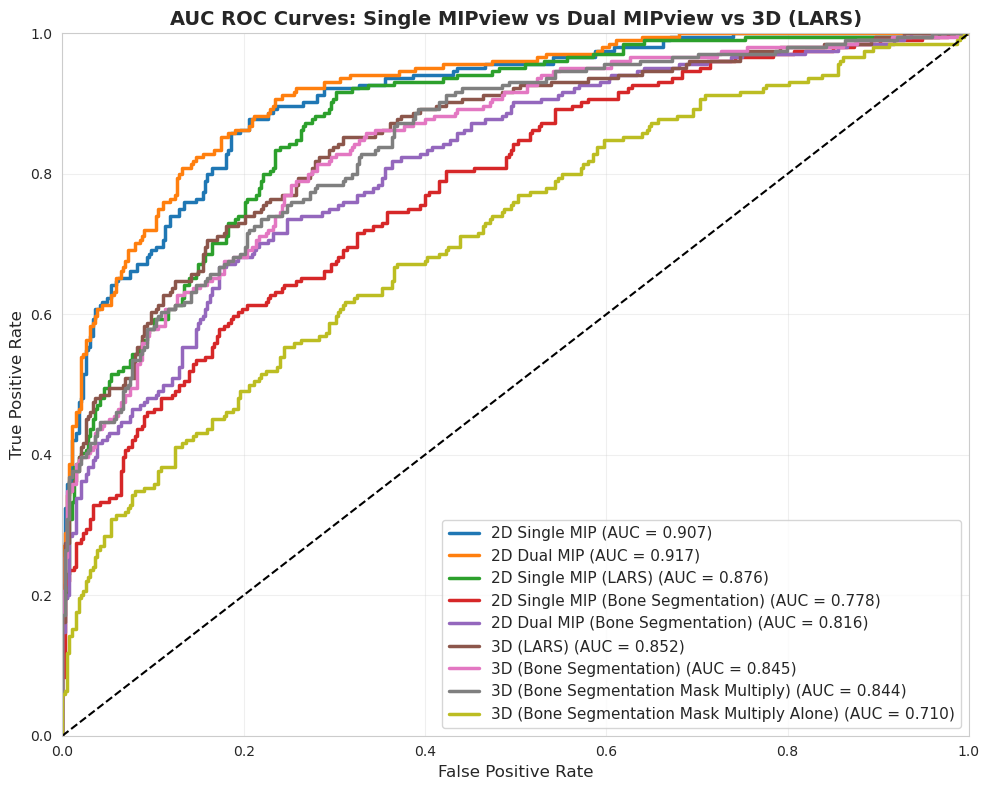

In [15]:


def average_df_by_filepath(df):
    return df.groupby('filepath', as_index=False).agg({
        'PET_jco': 'first',
        'PET_imwg': 'first',
        'probs_mean': 'mean',
        'probs_max': 'mean'
    })

# Prepare averaged data for ROC curves
fig, ax = plt.subplots(figsize=(10, 8))

averaged_mega_dict = {name: average_df_by_filepath(df) for name, df in mega_dict.items()}

# Plot all averaged models
models = list(averaged_mega_dict.items())

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22']

for (model_name, df), color in zip(models, colors):
    # Use PET_jco as binary label (convert to binary if needed)
    y_true = df['PET_jco'].values
    y_pred = df[['probs_mean', 'probs_max']].mean(axis=1).values
    
    # Calculate ROC curve and AUC
    fpr, tpr, _ = roc_curve(y_true, y_pred)
    roc_auc = auc(fpr, tpr)
    
    # Plot ROC curve
    ax.plot(fpr, tpr, color=color, lw=2.5, label=f'{model_name} (AUC = {roc_auc:.3f})')

# Plot diagonal line
ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='')

# Formatting
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('AUC ROC Curves: Single MIPview vs Dual MIPview vs 3D (LARS)', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])

plt.tight_layout()
plt.show()

In [38]:
y_true.shape

(592,)

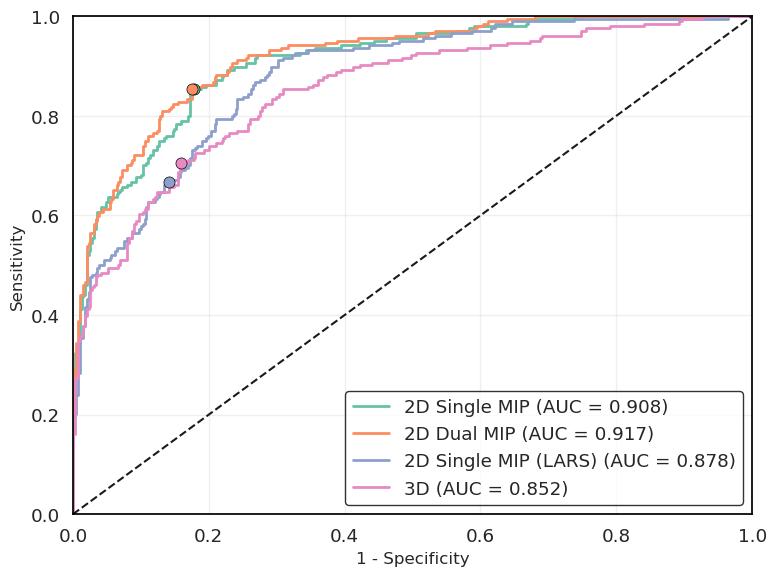

In [110]:
# limited
def average_df_by_filepath(df):
    return df.groupby('filepath', as_index=False).agg({
        'PET_jco': 'first',
        'PET_imwg': 'first',
        'probs_mean': 'mean',
        'probs_max': 'mean'
    })



# Prepare averaged data for ROC curves
fig, ax = plt.subplots(figsize=(8, 6))

averaged_mega_dict = {name: average_df_by_filepath(df) for name, df in mega_dict.items()}

# Plot all averaged models
models = [
    ('2D Single MIP', averaged_mega_dict['2D Single MIP']),
    ('2D Dual MIP', averaged_mega_dict['2D Dual MIP']),
    ('2D Single MIP (LARS)', averaged_mega_dict['2D Single MIP (LARS)']),
    ('3D', averaged_mega_dict['3D'])
]
# use sns set 2 for colors
sns.set_palette("Set2")

colors = sns.color_palette("Set2")[:4]
thresholds = [0.300, 0.217, .359923, 0.229]
for (model_name, df), color, thresh in zip(models, colors, thresholds):
    # Use PET_jco as binary label (convert to binary if needed)
    y_true = df['PET_jco'].values
    y_pred = df[['probs_mean']].mean(axis=1).values
    
    # Calculate ROC curve and AUC
    fpr, tpr, thresholds_list = roc_curve(y_true, y_pred, drop_intermediate = False)
    roc_auc = auc(fpr, tpr)
    
    # Plot ROC curve
    ax.plot(fpr, tpr, color=color,
        lw=2, label=f"{model_name} (AUC = {roc_auc:.3f})")
    

    # plot threshold point
    thresh_fpr = fpr[np.argmin(np.abs(thresholds_list - thresh))]
    thresh_tpr = tpr[np.argmin(np.abs(thresholds_list - thresh))]

    # black border on point
    # do not add to legend
    ax.plot(thresh_fpr, thresh_tpr, marker='o', color=color, markersize=8, label='_nolegend_',
            zorder = 5, markeredgecolor='black', markeredgewidth=.5)


# Plot diagonal line
ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='')

# Formatting
ax.set_xlabel('1 - Specificity', fontsize=12)
ax.set_ylabel('Sensitivity', fontsize=12)
ax.legend(loc='lower right', fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])

# legend black border
for _, spine in plt.gca().spines.items():
   spine.set_edgecolor('black')

leg = plt.legend()
leg.get_frame().set_edgecolor('black')


plt.tight_layout()
# top is being cut off
plt.show()

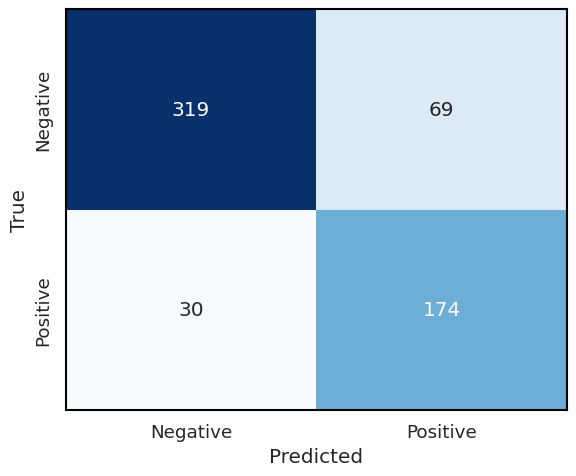

In [100]:
# confusion matrix at threshold for 2D single MIP
from sklearn.metrics import confusion_matrix
# Get the specific model's data
model_name = '2D Single MIP'
df = averaged_mega_dict[model_name]
y_true = df['PET_jco'].values
y_pred = df[['probs_mean']].mean(axis=1).values
threshold = 0.300
y_pred_binary = (y_pred >= threshold).astype(int)
cm = confusion_matrix(y_true, y_pred_binary)

# plot with seaborn heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.xticks([0.5, 1.5], ['Negative', 'Positive'])
plt.yticks([0.5, 1.5], ['Negative', 'Positive'])

# add black border to matrix
for _, spine in plt.gca().spines.items():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color('black')

plt.tight_layout()
plt.show()

In [ ]:
'/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_thumbnails_png/5222188_pt_0.png'

([], [])

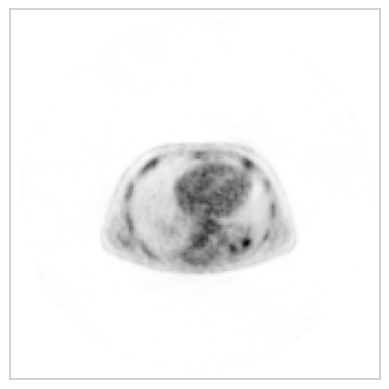

In [ ]:
# open h5
pet_arr = h5py.File('/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5/5222188/5222188_pt_0.h5')['image'][:]
#ct_arr = h5py.File('/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5/5222188/5222188_pt_0.h5')['image'][:]

plt.imshow(pet_arr[:,:,110], cmap='gray_r')
plt.grid(False)
plt.xticks([])
plt.yticks([])

